<a href="https://colab.research.google.com/github/jorgemx546/rutas-inundacion/blob/main/rutas_inundacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rutas de evacuación en zona inundada
**Actividad:** Cuando el camino más corto no es el mejor · Fundamentos de Inteligencia Artificial

**Equipo:**
Jorge Navarrete Tzuc

Jarett Osiel Itzá Santizo

Erick Yahir Salinas Beatriz

Daniel Eduaro Ríos Astudillo

Un agente debe llegar desde una zona afectada hasta un refugio. El terreno tiene niveles de inundación con distinto riesgo, y algunas zonas están bloqueadas. Comparamos BFS, Dijkstra y A* para mostrar la diferencia entre encontrar *una* ruta y encontrar la ruta *conveniente*.

In [1]:
import heapq, time
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Niveles de terreno según el grado de inundación
SECO, BAJO, MEDIO, ALTO, BLOQUEADO = 0, 1, 2, 3, 4
# Riesgo de cada nivel (BLOQUEADO nunca se pisa, así que su riesgo no se usa)
RIESGO = np.array([0, 1, 3, 6, 0])
PESO_RIESGO = 3  # cuánto penaliza el riesgo en el costo

def crear_terreno():
    g = np.zeros((10, 10), dtype=int)
    g[4, :] = BLOQUEADO      # "río" que cruza el mapa
    g[4, 1] = ALTO           # cruce corto pero muy inundado
    g[4, 8] = SECO           # puente seguro pero lejano
    g[3, 0:3] = BAJO         # inundación leve antes del cruce
    g[5, 0:3] = MEDIO        # inundación media después del cruce
    return g

INICIO, REFUGIO = (0, 1), (9, 1)
grid = crear_terreno()

In [2]:
def vecinos(grid, pos):
    f, c = pos
    for df, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
        nf, nc = f + df, c + dc
        if 0 <= nf < grid.shape[0] and 0 <= nc < grid.shape[1] and grid[nf, nc] != BLOQUEADO:
            yield (nf, nc)

def costo_celda(grid, pos, peso):
    # Entrar a una celda cuesta 1 paso + penalización por riesgo
    return 1 + peso * RIESGO[grid[pos]]

def costo_ruta(grid, ruta, peso):
    # La celda de inicio no se cuenta: el agente ya está ahí
    return float(sum(costo_celda(grid, p, peso) for p in ruta[1:]))

def riesgo_ruta(grid, ruta):
    # Mismo criterio que el costo: se suman las celdas a las que se entra
    return int(sum(RIESGO[grid[p]] for p in ruta[1:]))

def reconstruir(padres, meta):
    ruta, actual = [], meta
    while actual is not None:
        ruta.append(actual)
        actual = padres[actual]
    return ruta[::-1]

def resultado(nombre, grid, padres, meta, peso, expandidos, t0, costo_interno=None):
    ms = (time.perf_counter() - t0) * 1000
    if meta not in padres:  # refugio inaccesible
        return dict(algoritmo=nombre, ruta=None, costo=float('inf'), pasos=None,
                    riesgo=None, expandidos=expandidos, tiempo_ms=ms)
    ruta = reconstruir(padres, meta)
    # Dijkstra y A* reportan el costo que acumularon durante la búsqueda.
    # El validador lo recalcula por separado: si no coinciden, hay un error.
    costo = costo_ruta(grid, ruta, peso) if costo_interno is None else float(costo_interno)
    return dict(algoritmo=nombre, ruta=ruta, costo=costo, pasos=len(ruta) - 1,
                riesgo=riesgo_ruta(grid, ruta), expandidos=expandidos, tiempo_ms=ms)

In [3]:
def bfs(grid, inicio, meta, peso=PESO_RIESGO):
    """Menos pasos. Ignora el riesgo al decidir; su costo se calcula después."""
    t0 = time.perf_counter()
    cola = deque([inicio]); padres = {inicio: None}; exp = 0
    while cola:
        actual = cola.popleft(); exp += 1
        if actual == meta: break
        for v in vecinos(grid, actual):
            if v not in padres:
                padres[v] = actual; cola.append(v)
    return resultado("BFS", grid, padres, meta, peso, exp, t0)

def _busqueda_costo(nombre, grid, inicio, meta, peso, usar_heuristica, costo_paso):
    t0 = time.perf_counter()
    # Heurística Manhattan: admisible porque cada paso cuesta al menos 1
    h = (lambda p: abs(p[0] - meta[0]) + abs(p[1] - meta[1])) if usar_heuristica else (lambda p: 0)
    g = {inicio: 0.0}; padres = {inicio: None}; cerrados = set(); exp = 0
    heap = [(h(inicio), 0, inicio)]; desempate = 1
    while heap:
        _, _, actual = heapq.heappop(heap)
        if actual in cerrados: continue
        cerrados.add(actual); exp += 1
        if actual == meta: break
        for v in vecinos(grid, actual):
            nuevo = g[actual] + costo_paso(grid, v, peso)
            if v not in g or nuevo < g[v]:
                g[v] = nuevo; padres[v] = actual
                heapq.heappush(heap, (nuevo + h(v), desempate, v)); desempate += 1
    return resultado(nombre, grid, padres, meta, peso, exp, t0, g.get(meta))

# costo_paso permite inyectar un error a propósito en la prueba adicional (celda 8)
def dijkstra(grid, inicio, meta, peso=PESO_RIESGO, costo_paso=costo_celda):
    return _busqueda_costo("Dijkstra", grid, inicio, meta, peso, False, costo_paso)

def a_estrella(grid, inicio, meta, peso=PESO_RIESGO, costo_paso=costo_celda):
    return _busqueda_costo("A*", grid, inicio, meta, peso, True, costo_paso)

ALGORITMOS = [bfs, dijkstra, a_estrella]

### Explicación: terreno y algoritmos (Jorge)

- **Terreno.** Cuadrícula de 10×10. Cada celda tiene un nivel: seco, inundación baja, media, alta o bloqueado. El riesgo de cada nivel es 0, 1, 3 y 6; las celdas bloqueadas no se pueden pisar.
- **Mapa de prueba.** Un río bloquea la fila 4. Hay dos formas de cruzarlo: un cruce corto con inundación alta en (4,1) y un puente seco pero lejano en (4,8).
- **Costo.** Entrar a una celda cuesta `1 + PESO_RIESGO × riesgo`, con `PESO_RIESGO = 3`.
- **BFS** busca la ruta con menos pasos y no mira el riesgo: encuentra *una* ruta.
- **Dijkstra** busca la ruta de menor costo total: encuentra la ruta *conveniente*.
- **A\*** hace lo mismo que Dijkstra, pero usa la distancia Manhattan para explorar menos. Esa heurística nunca sobreestima porque cada paso cuesta al menos 1, así que A* sigue encontrando el costo mínimo.
- **Resultado medido:** BFS cruza el agua en 9 pasos con costo 39; Dijkstra y A* van por el puente en 23 pasos con costo 23. A* expandió 75 nodos y Dijkstra 86.

In [4]:
def validar_ruta(grid, ruta, inicio, meta, peso, costo_reportado=None):
    """Devuelve la lista de errores; vacía = ruta válida."""
    if not ruta: return ["la ruta está vacía"]
    errores = []
    if ruta[0] != inicio: errores.append("no empieza en el inicio")
    if ruta[-1] != meta: errores.append("no termina en el refugio")
    for p in ruta:
        if not (0 <= p[0] < grid.shape[0] and 0 <= p[1] < grid.shape[1]):
            errores.append(f"{p} fuera del mapa"); return errores
        if grid[p] == BLOQUEADO: errores.append(f"atraviesa celda bloqueada {p}")
    for a, b in zip(ruta, ruta[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1: errores.append(f"salto inválido {a}->{b}")
    if costo_reportado is not None and not errores:
        if abs(costo_ruta(grid, ruta, peso) - costo_reportado) > 1e-9:
            errores.append("el costo reportado no coincide con el recalculado")
    return errores

def comparar(grid, inicio, meta, peso=PESO_RIESGO, algoritmos=ALGORITMOS):
    filas = []
    for alg in algoritmos:
        r = alg(grid, inicio, meta, peso)
        if r["ruta"] is None: estado = "sin ruta"
        else: estado = "OK" if not validar_ruta(grid, r["ruta"], inicio, meta, peso, r["costo"]) else "INVÁLIDA"
        filas.append(dict(algoritmo=r["algoritmo"], costo=r["costo"], pasos=r["pasos"], riesgo=r["riesgo"],
                          expandidos=r["expandidos"], tiempo_ms=round(r["tiempo_ms"], 3), validación=estado))
    return pd.DataFrame(filas)

COLORES = ['#e8f5e9', '#bbdefb', '#64b5f6', '#1565c0', '#212121']
ESTILOS = {"BFS": ("red", "--", 3), "Dijkstra": ("orange", "-", 4), "A*": ("black", ":", 2)}

def mostrar(grid, titulo, peso=PESO_RIESGO, inicio=INICIO, meta=REFUGIO):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(grid, cmap=ListedColormap(COLORES), vmin=0, vmax=4)
    for alg in ALGORITMOS:
        r = alg(grid, inicio, meta, peso)
        if r["ruta"]:
            color, estilo, ancho = ESTILOS[r["algoritmo"]]
            ax.plot([p[1] for p in r["ruta"]], [p[0] for p in r["ruta"]],
                    color=color, linestyle=estilo, linewidth=ancho, label=r["algoritmo"])
    ax.scatter(inicio[1], inicio[0], s=150, c='lime', edgecolors='k', zorder=5, label='Inicio')
    ax.scatter(meta[1], meta[0], s=150, c='yellow', marker='*', edgecolors='k', zorder=5, label='Refugio')
    ax.set_title(titulo); ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.show()
    print("Leyenda: verde claro=seco | azul claro=inundación baja | azul=media | azul oscuro=alta | negro=bloqueado")

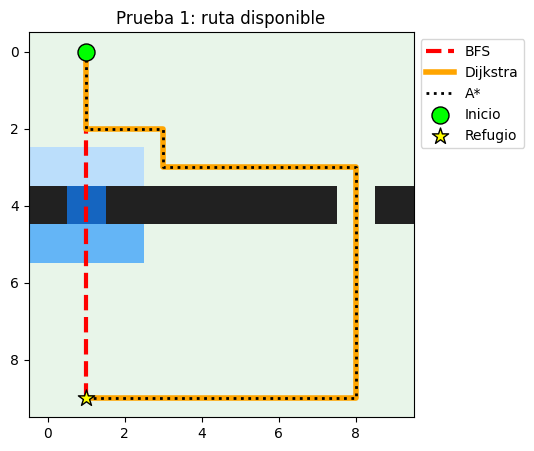

Leyenda: verde claro=seco | azul claro=inundación baja | azul=media | azul oscuro=alta | negro=bloqueado


,algoritmo,costo,pasos,riesgo,expandidos,tiempo_ms,validación
0,BFS,39.0,9,10,49,0.273,OK
1,Dijkstra,23.0,23,0,86,1.125,OK
2,A*,23.0,23,0,75,1.056,OK


✔ Prueba 1: los tres algoritmos encuentran una ruta válida


In [5]:
# Prueba 1: existe una ruta disponible hasta el refugio
mostrar(grid, "Prueba 1: ruta disponible")
t1 = comparar(grid, INICIO, REFUGIO)
display(t1)
assert (t1["validación"] == "OK").all(), "alguna ruta no pasó el validador"
print("✔ Prueba 1: los tres algoritmos encuentran una ruta válida")

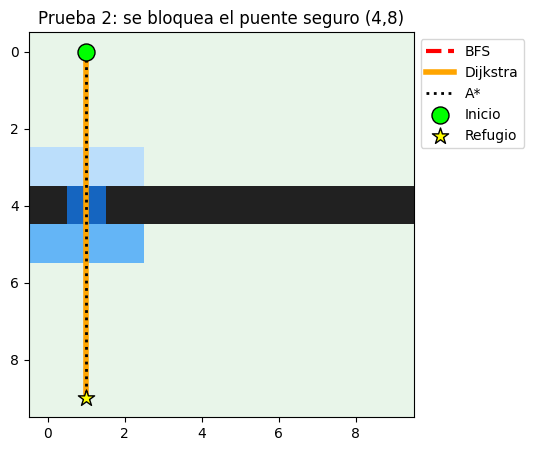

Leyenda: verde claro=seco | azul claro=inundación baja | azul=media | azul oscuro=alta | negro=bloqueado


,algoritmo,costo,pasos,riesgo,expandidos,tiempo_ms,validación
0,BFS,39.0,9,10,49,0.285,OK
1,Dijkstra,39.0,9,10,51,0.634,OK
2,A*,39.0,9,10,46,4.895,OK


✔ Prueba 2: la ruta cambia y ya no pasa por la celda bloqueada


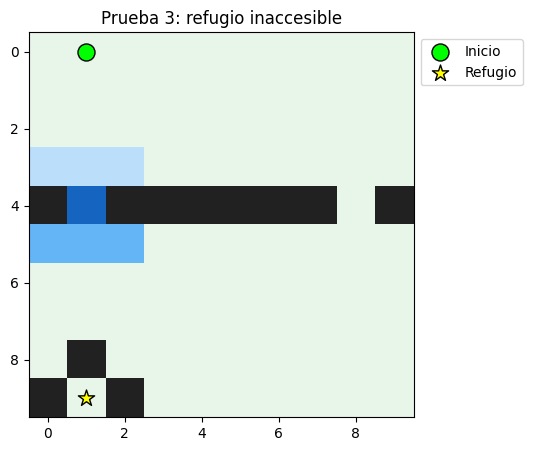

Leyenda: verde claro=seco | azul claro=inundación baja | azul=media | azul oscuro=alta | negro=bloqueado


,algoritmo,costo,pasos,riesgo,expandidos,tiempo_ms,validación
0,BFS,inf,None,None,88,0.477,sin ruta
1,Dijkstra,inf,None,None,88,4.931,sin ruta
2,A*,inf,None,None,88,1.057,sin ruta


✔ Prueba 3: los tres algoritmos reportan 'sin ruta' sin fallar


In [6]:
# Prueba 2: se bloquea una celda que formaba parte de la ruta
ruta_ant = dijkstra(grid, INICIO, REFUGIO)["ruta"]
celda = (4, 8)
assert celda in ruta_ant, "la celda elegida no era parte de la ruta anterior"
g2 = grid.copy(); g2[celda] = BLOQUEADO
mostrar(g2, "Prueba 2: se bloquea el puente seguro (4,8)")
t2 = comparar(g2, INICIO, REFUGIO)
display(t2)
ruta_nueva = dijkstra(g2, INICIO, REFUGIO)["ruta"]
assert ruta_nueva is not None and celda not in ruta_nueva and ruta_nueva != ruta_ant
assert (t2["validación"] == "OK").all()
print("✔ Prueba 2: la ruta cambia y ya no pasa por la celda bloqueada")

# Prueba 3: el refugio queda rodeado de celdas bloqueadas
g3 = grid.copy()
for p in [(8, 1), (9, 0), (9, 2)]:
    g3[p] = BLOQUEADO
mostrar(g3, "Prueba 3: refugio inaccesible")
t3 = comparar(g3, INICIO, REFUGIO)
display(t3)
assert (t3["validación"] == "sin ruta").all(), "algún algoritmo inventó una ruta"
print("✔ Prueba 3: los tres algoritmos reportan 'sin ruta' sin fallar")

### Explicación: validador, comparación y pruebas 1 a 3 (Jarett)

- **Validador.** `validar_ruta` revisa que la ruta empiece en el inicio, termine en el refugio, avance solo entre celdas vecinas y no pise celdas bloqueadas. También recalcula el costo y lo compara con el que reportó el algoritmo.
- **Tabla comparativa.** Para cada algoritmo muestra costo, pasos, riesgo acumulado, nodos expandidos (cuánto trabajo hizo) y tiempo en milisegundos, todo medido en la ejecución.
- **Prueba 1.** Los tres algoritmos encuentran una ruta válida. BFS da la más corta (9 pasos, costo 39); Dijkstra y A* dan la más barata (23 pasos, costo 23).
- **Prueba 2.** Al bloquear el puente (4,8), que era parte de la ruta, Dijkstra cambia de ruta y cruza por (4,1) con costo 39.
- **Prueba 3.** Con el refugio rodeado de celdas bloqueadas, los tres algoritmos responden "sin ruta" y costo infinito, sin errores y sin inventar una ruta.

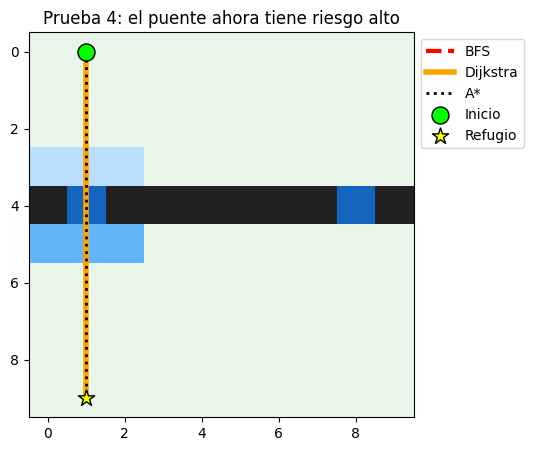

Leyenda: verde claro=seco | azul claro=inundación baja | azul=media | azul oscuro=alta | negro=bloqueado


,algoritmo,costo,pasos,riesgo,expandidos,tiempo_ms,validación
0,BFS,39.0,9,10,49,0.151,OK
1,Dijkstra,39.0,9,10,85,0.548,OK
2,A*,39.0,9,10,46,0.306,OK


✔ Prueba 4: al subir el riesgo del puente, Dijkstra cambia de ruta


,peso_riesgo,cruza_por,costo,pasos,riesgo
0,0,"cruce riesgoso (4,1)",9.0,9,10
1,1,"cruce riesgoso (4,1)",19.0,9,10
2,2,"puente seguro (4,8)",23.0,23,0
3,3,"puente seguro (4,8)",23.0,23,0
4,5,"puente seguro (4,8)",23.0,23,0
5,10,"puente seguro (4,8)",23.0,23,0


,algoritmo,costo,pasos,riesgo,expandidos,tiempo_ms,validación
0,BFS,39.0,9,10,49,0.235,OK
1,Dijkstra,23.0,23,0,86,1.512,OK
2,A*,23.0,23,0,75,0.799,OK


✔ Prueba 5: la ruta más corta (BFS) no es la de menor costo (Dijkstra)


In [8]:
# Prueba 4: sube la inundación del puente y se vuelve a buscar
g4 = grid.copy(); g4[4, 8] = ALTO
mostrar(g4, "Prueba 4: el puente ahora tiene riesgo alto")
display(comparar(g4, INICIO, REFUGIO))
antes = dijkstra(grid, INICIO, REFUGIO)["ruta"]
despues = dijkstra(g4, INICIO, REFUGIO)["ruta"]
assert (4, 8) in antes and (4, 8) not in despues, "la decisión no cambió con el nuevo riesgo"
print("✔ Prueba 4: al subir el riesgo del puente, Dijkstra cambia de ruta")

# Prueba 5: variar el peso del riesgo y ver cuándo cambia la decisión
filas = []
for w in [0, 1, 2, 3, 5, 10]:
    r = dijkstra(grid, INICIO, REFUGIO, w)
    filas.append(dict(peso_riesgo=w, cruza_por="cruce riesgoso (4,1)" if (4, 1) in r["ruta"] else "puente seguro (4,8)",
                      costo=r["costo"], pasos=r["pasos"], riesgo=r["riesgo"]))
t5 = pd.DataFrame(filas)
display(t5)
assert t5["cruza_por"].nunique() == 2, "el peso del riesgo nunca cambió la decisión"

# Camino más corto (BFS) vs. más conveniente (Dijkstra) con el peso por defecto
t5b = comparar(grid, INICIO, REFUGIO)
display(t5b)
bfs_r, dij_r = t5b.iloc[0], t5b.iloc[1]
assert bfs_r["pasos"] < dij_r["pasos"] and bfs_r["costo"] > dij_r["costo"]
print("✔ Prueba 5: la ruta más corta (BFS) no es la de menor costo (Dijkstra)")

In [9]:
# Prueba adicional: ¿las pruebas detectan un error real en la búsqueda?
def prueba_aleatoria(algoritmos, n_terrenos=300, semilla=42):
    """Compara BFS, Dijkstra y A* en terrenos aleatorios y devuelve los fallos."""
    rng = np.random.default_rng(semilla)
    fallos = []
    for i in range(n_terrenos):
        n = int(rng.integers(5, 12))
        gg = rng.choice(5, size=(n, n), p=[.4, .2, .15, .1, .15])
        gg[0, 0] = SECO; gg[-1, -1] = SECO
        w = float(rng.integers(0, 6)); ini, meta = (0, 0), (n - 1, n - 1)
        rb, rd, ra = (f(gg, ini, meta, w) for f in algoritmos)
        if len({rb["ruta"] is None, rd["ruta"] is None, ra["ruta"] is None}) > 1:
            fallos.append((i, "desacuerdo sobre existencia de ruta")); continue
        if rd["ruta"] is None: continue
        if abs(rd["costo"] - ra["costo"]) > 1e-9: fallos.append((i, "Dijkstra != A*"))
        if rb["costo"] < rd["costo"] - 1e-9: fallos.append((i, "BFS mejor que Dijkstra"))
        for r in (rb, rd, ra):
            if validar_ruta(gg, r["ruta"], ini, meta, w, r["costo"]):
                fallos.append((i, f"ruta inválida de {r['algoritmo']}"))
    return fallos

# (a) La implementación actual no debe tener fallos
fallos = prueba_aleatoria(ALGORITMOS)
print(f"Implementación actual: {len(fallos)} fallos en 300 terrenos")
assert not fallos, fallos[:5]

# (b) Se inyecta un error a propósito: Dijkstra y A* suman 1 por paso e ignoran el riesgo.
#     Si la prueba no lo detecta, la prueba no sirve.
def costo_sin_riesgo(grid, pos, peso):
    return 1

ALGORITMOS_CON_ERROR = [
    bfs,
    lambda g, i, m, p=PESO_RIESGO: dijkstra(g, i, m, p, costo_paso=costo_sin_riesgo),
    lambda g, i, m, p=PESO_RIESGO: a_estrella(g, i, m, p, costo_paso=costo_sin_riesgo),
]
display(comparar(grid, INICIO, REFUGIO, algoritmos=ALGORITMOS_CON_ERROR))
fallos_error = prueba_aleatoria(ALGORITMOS_CON_ERROR)
print(f"Con el error inyectado: {len(fallos_error)} fallos detectados en 300 terrenos")
print("Ejemplos:", fallos_error[:3])
assert fallos_error, "la prueba NO detectó el error inyectado"
print("✔ Prueba adicional: la prueba aleatoria detecta el error inyectado")

Implementación actual: 0 fallos en 300 terrenos


,algoritmo,costo,pasos,riesgo,expandidos,tiempo_ms,validación
0,BFS,39.0,9,10,49,0.139,OK
1,Dijkstra,9.0,9,10,49,0.270,INVÁLIDA
2,A*,9.0,9,10,10,0.063,INVÁLIDA


Con el error inyectado: 474 fallos detectados en 300 terrenos
Ejemplos: [(0, 'ruta inválida de Dijkstra'), (0, 'ruta inválida de A*'), (1, 'ruta inválida de Dijkstra')]
✔ Prueba adicional: la prueba aleatoria detecta el error inyectado
